In [1]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier  # should work now ✅


In [3]:
df = pd.read_csv("dataset_academic.csv")
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (80000, 31)


,student_id,age,gender,major,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,...,screen_time,study_environment,access_to_tutoring,family_income_range,parental_support_level,motivation_level,exam_anxiety_score,learning_style,time_management_score,exam_score
0,100000,26,Male,Computer Science,7.645367,3.0,0.1,Yes,70.3,6.2,...,10.9,Co-Learning Group,Yes,High,9,7,8,Reading,3.0,100
1,100001,28,Male,Arts,5.700000,0.5,0.4,No,88.4,7.2,...,8.3,Co-Learning Group,Yes,Low,7,2,10,Reading,6.0,99
2,100002,17,Male,Arts,2.400000,4.2,0.7,No,82.1,9.2,...,8.0,Library,Yes,High,3,9,6,Kinesthetic,7.6,98
3,100003,27,Other,Psychology,3.400000,4.6,2.3,Yes,79.3,4.2,...,11.7,Co-Learning Group,Yes,Low,5,3,10,Reading,3.2,100
4,100004,25,Female,Business,4.700000,0.8,2.7,Yes,62.9,6.5,...,9.4,Quiet Room,Yes,Medium,9,1,10,Reading,7.1,98


In [4]:
print("\nMissing Values:\n", df.isna().sum())
df.dropna(inplace=True)
print("Shape after Removing NULL Values:", df.shape)



Missing Values:
 student_id                       0
age                              0
gender                           0
major                            0
study_hours_per_day              0
social_media_hours               0
netflix_hours                    0
part_time_job                    0
attendance_percentage            0
sleep_hours                      0
diet_quality                     0
exercise_frequency               0
parental_education_level         0
internet_quality                 0
mental_health_rating             0
extracurricular_participation    0
previous_gpa                     0
semester                         0
stress_level                     0
dropout_risk                     0
social_activity                  0
screen_time                      0
study_environment                0
access_to_tutoring               0
family_income_range              0
parental_support_level           0
motivation_level                 0
exam_anxiety_score               0
le

In [5]:
df.drop_duplicates(inplace=True)
print("Shape after Removing Duplicates:", df.shape)


Shape after Removing Duplicates: (80000, 31)


In [6]:
float_cols = df.select_dtypes(include="float64").columns
df[float_cols] = df[float_cols].astype("int64", errors='ignore')
df.dtypes


student_id                        int64
age                               int64
gender                           object
major                            object
study_hours_per_day               int64
social_media_hours                int64
netflix_hours                     int64
part_time_job                    object
attendance_percentage             int64
sleep_hours                       int64
diet_quality                     object
exercise_frequency                int64
parental_education_level         object
internet_quality                 object
mental_health_rating              int64
extracurricular_participation    object
previous_gpa                      int64
semester                          int64
stress_level                      int64
dropout_risk                     object
social_activity                   int64
screen_time                       int64
study_environment                object
access_to_tutoring               object
family_income_range              object


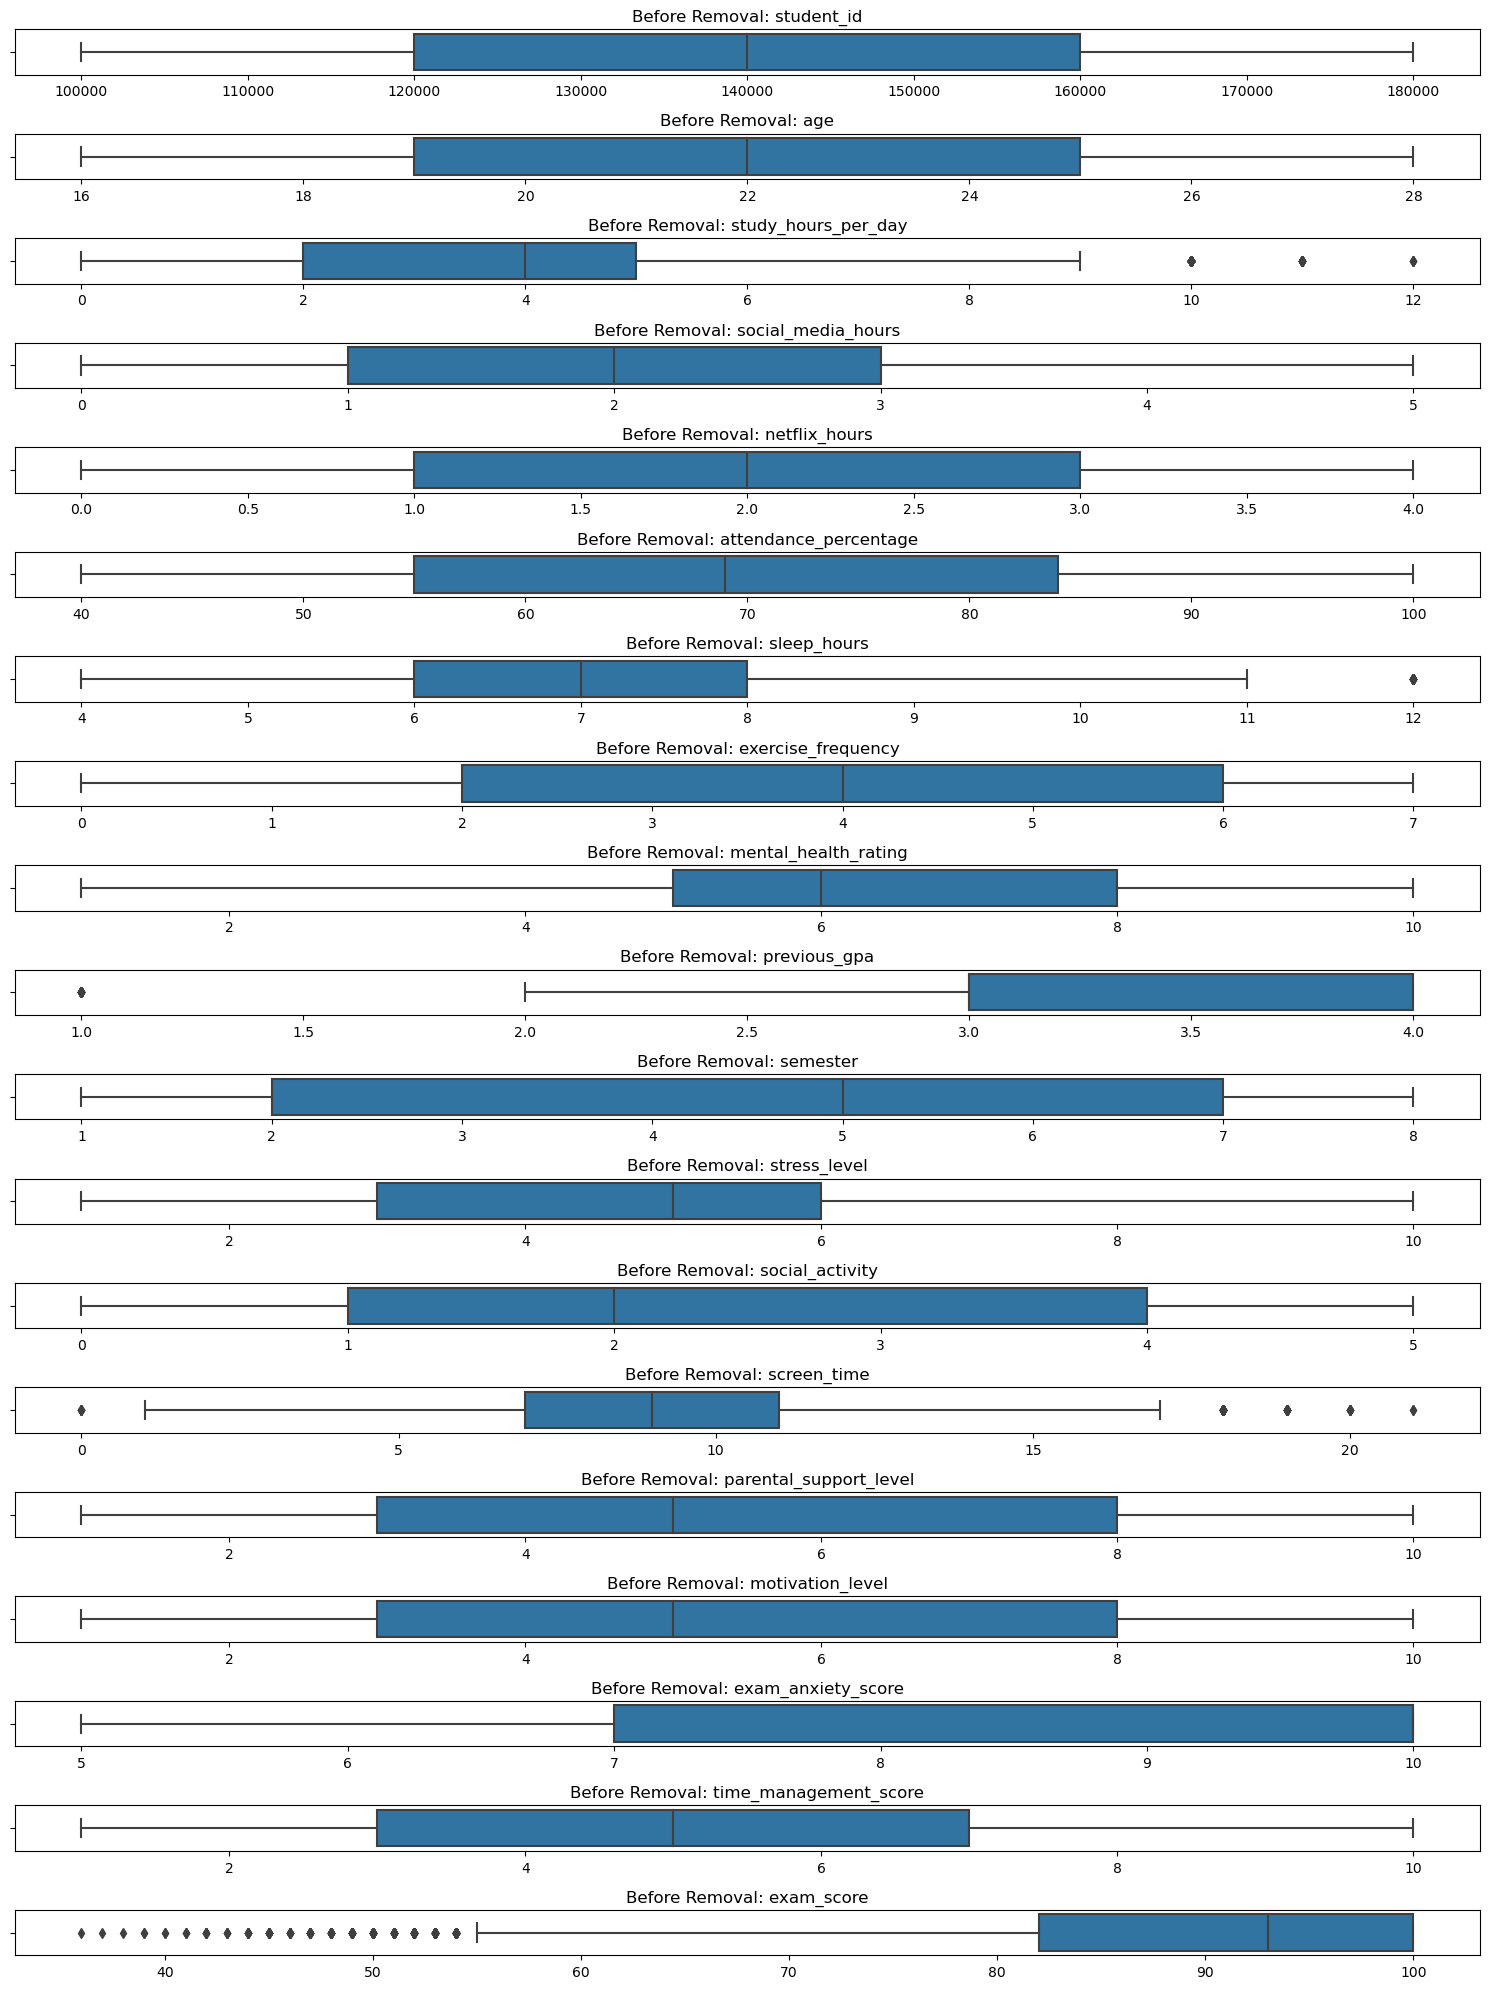

In [7]:
int_cols = list(df.select_dtypes(include='int64').columns)

fig, axes = plt.subplots(len(int_cols), 1, figsize=(15, 20))

for row, column in enumerate(int_cols):
    sns.boxplot(x=df[column].values, ax=axes[row])
    axes[row].set_title(f"Before Removal: {column}")

plt.tight_layout()
plt.show()


In [8]:
outlier_columns = ['study_hours_per_day', 'sleep_hours', 'previous_gpa', 'screen_time', 'exam_score']

print("Records Before Removing Outliers:", df.shape)

for col in outlier_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    min_threshold = q1 - iqr
    max_threshold = q3 + iqr

    outlier_index = df[(df[col] < min_threshold) | (df[col] > max_threshold)].index
    df.drop(outlier_index, inplace=True)

print("Records After Removing Outliers:", df.shape)


Records Before Removing Outliers: (80000, 31)
Records After Removing Outliers: (75850, 31)


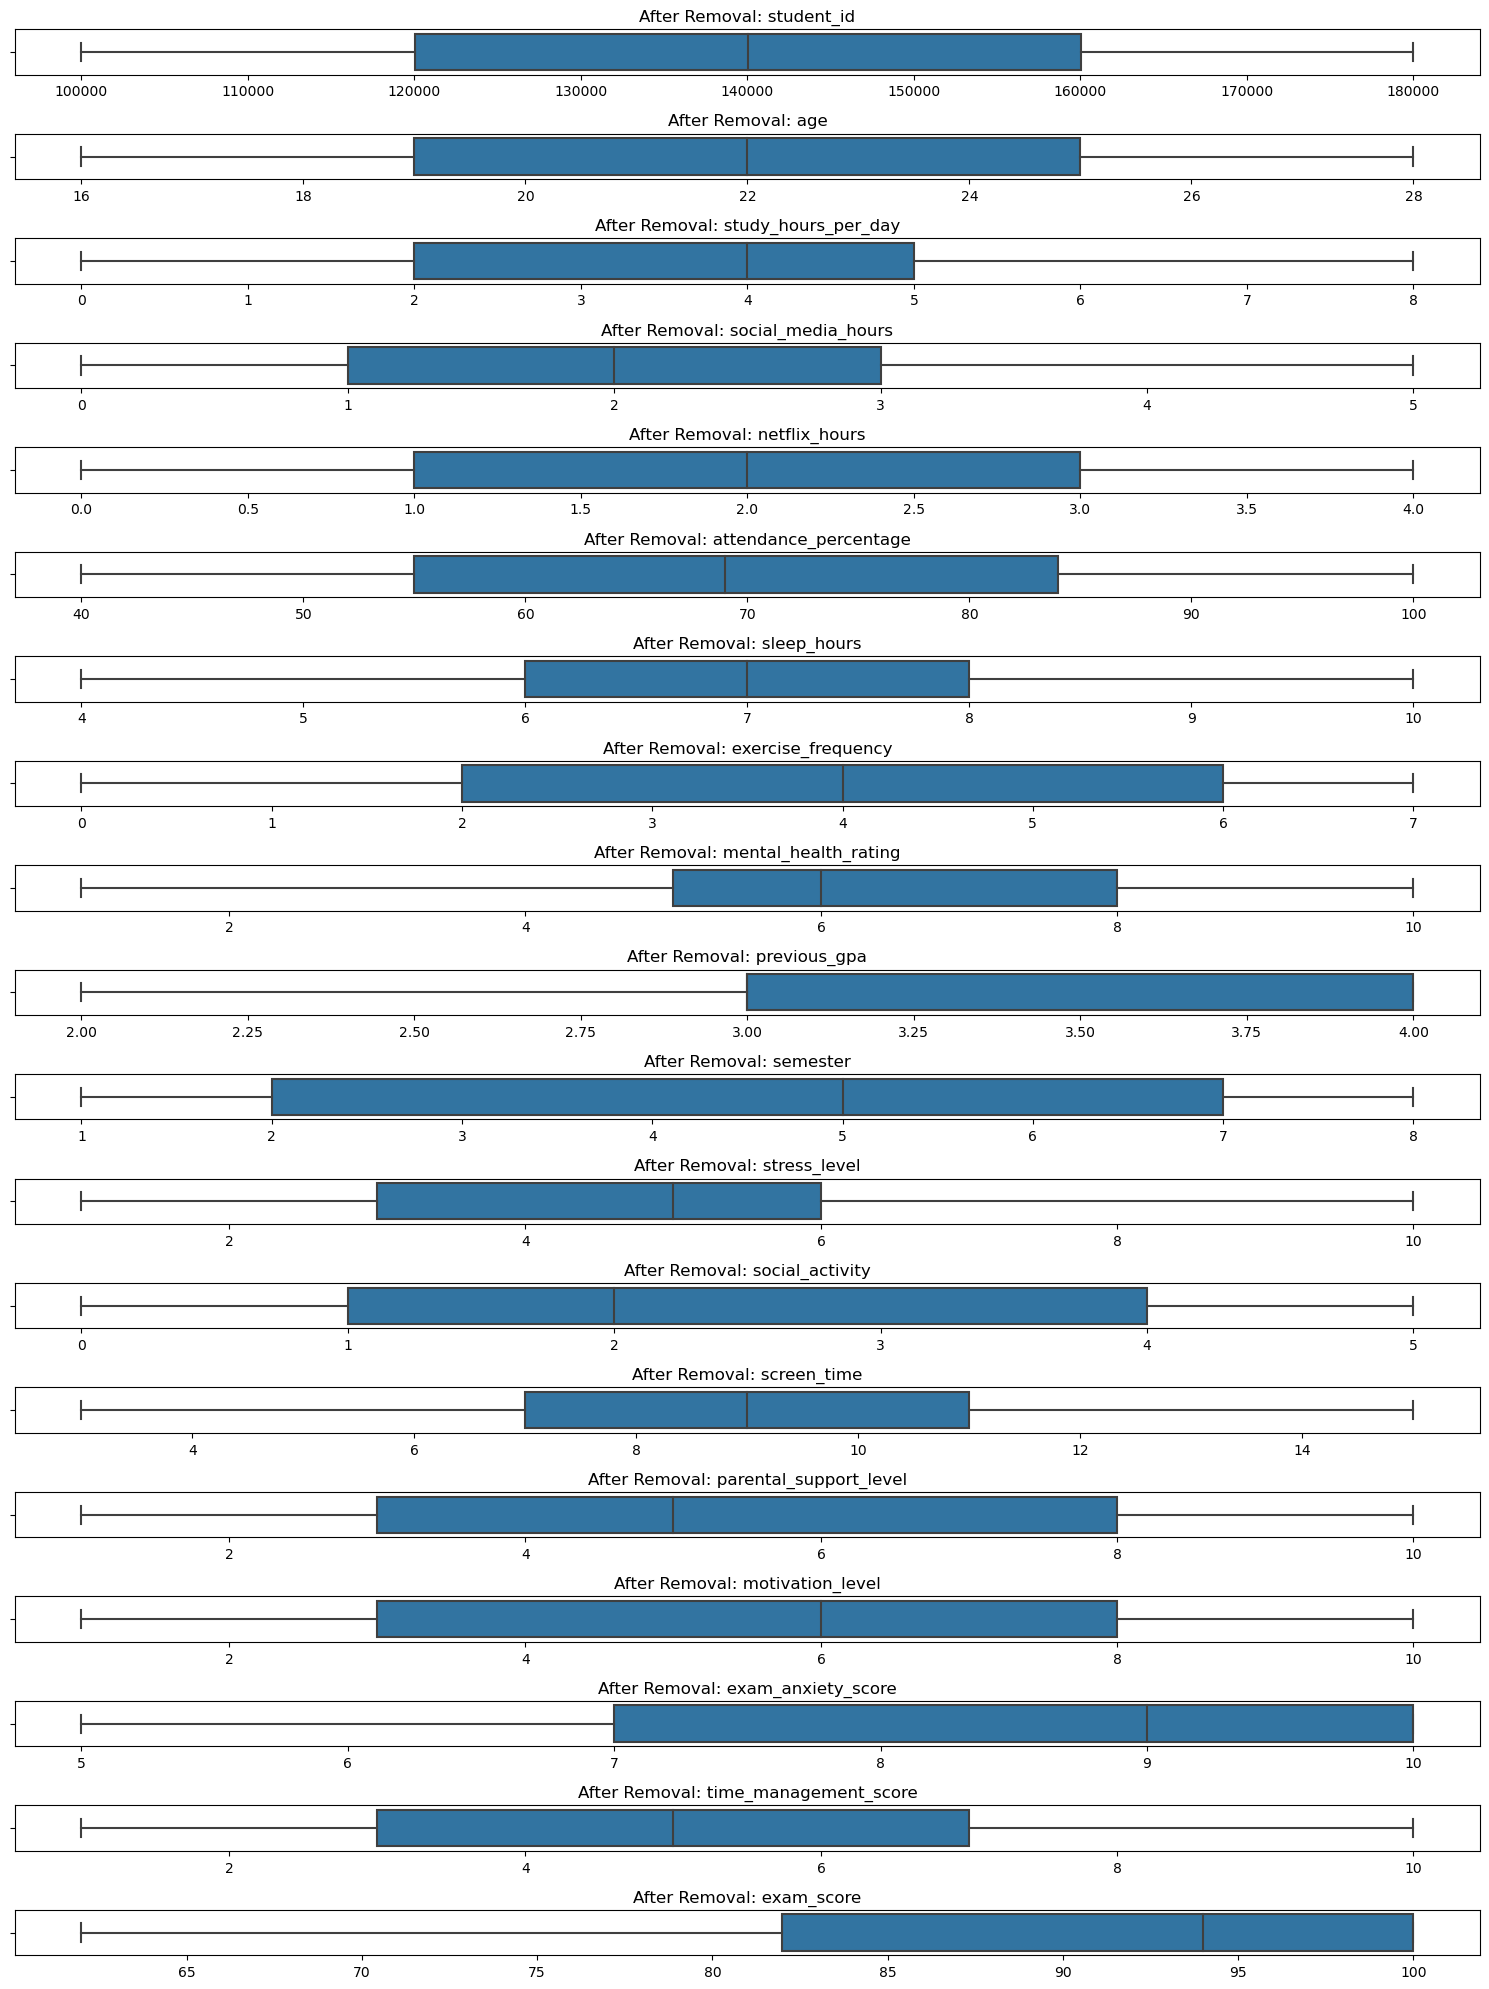

In [9]:
int_cols = list(df.select_dtypes(include='int64').columns)

fig, axes = plt.subplots(len(int_cols), 1, figsize=(15, 20))

for row, column in enumerate(int_cols):
    sns.boxplot(x=df[column].values, ax=axes[row])
    axes[row].set_title(f"After Removal: {column}")

plt.tight_layout()
plt.show()


In [10]:
df = df[df["age"].between(16, 28)]
df = df[df["attendance_percentage"].between(0,100)]
print("Final Cleaned Shape:", df.shape)


Final Cleaned Shape: (75850, 31)


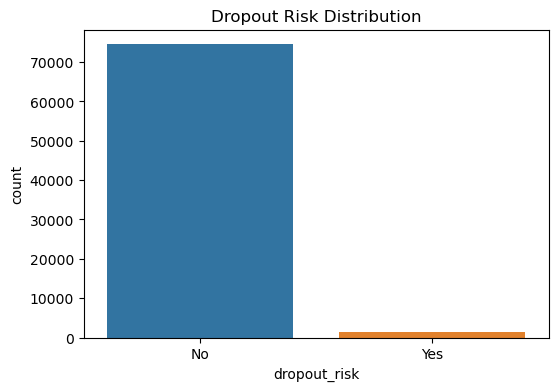

In [11]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="dropout_risk")
plt.title("Dropout Risk Distribution")
plt.show()


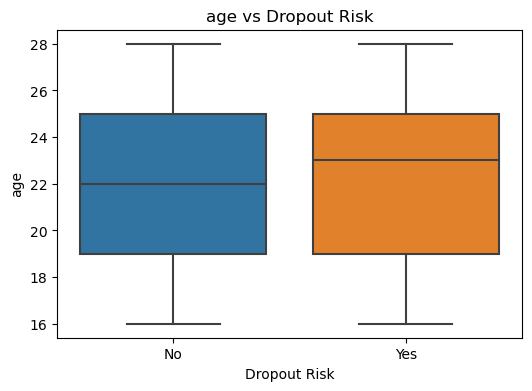

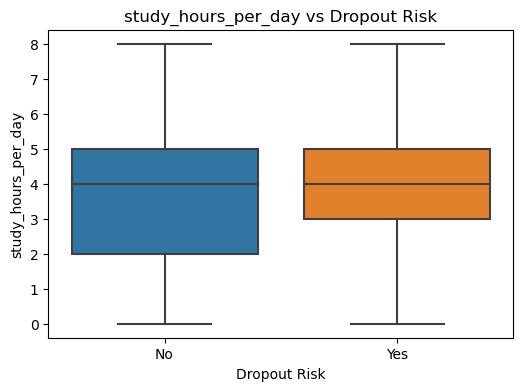

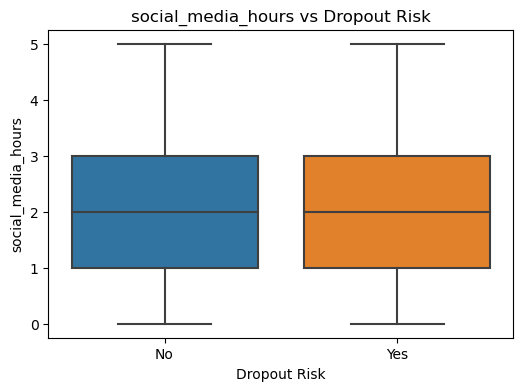

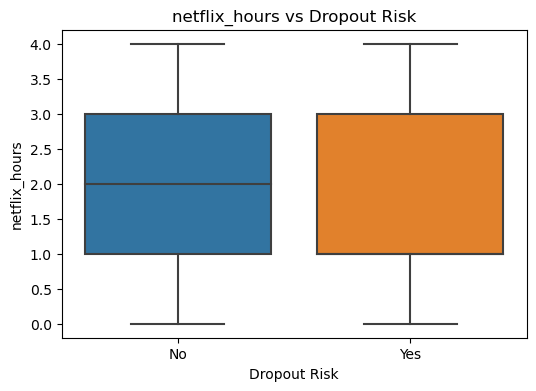

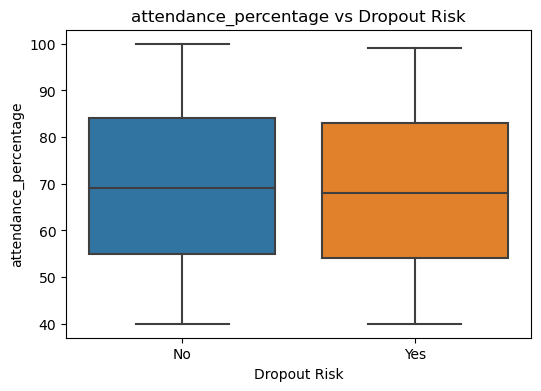

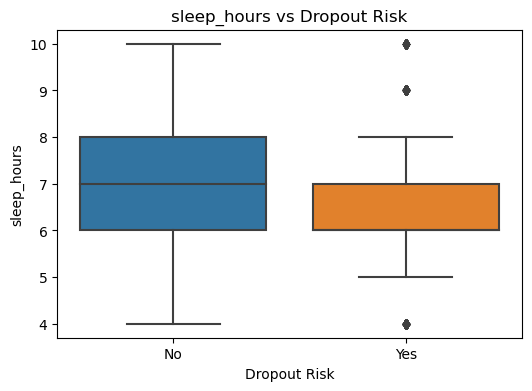

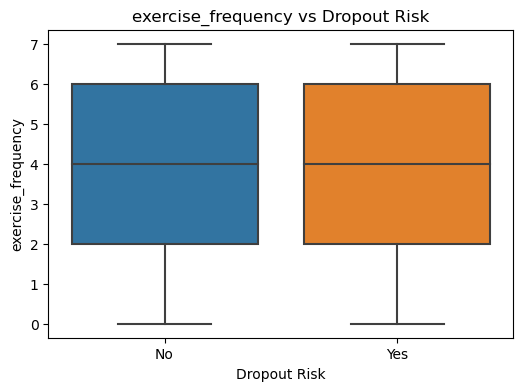

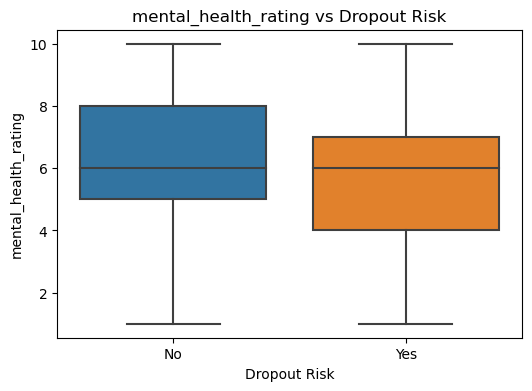

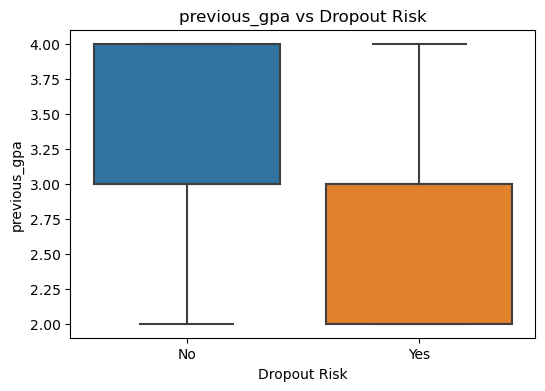

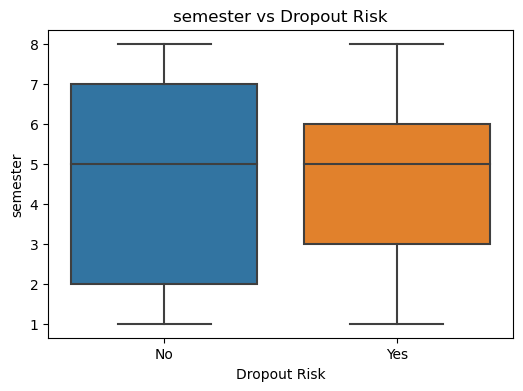

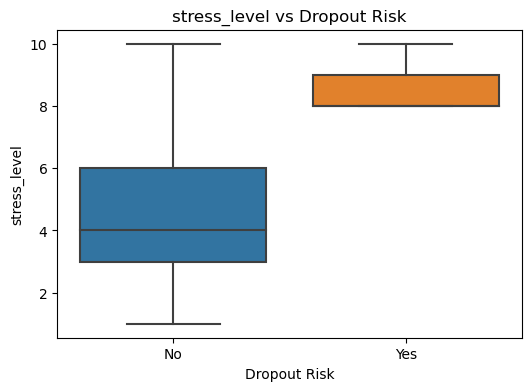

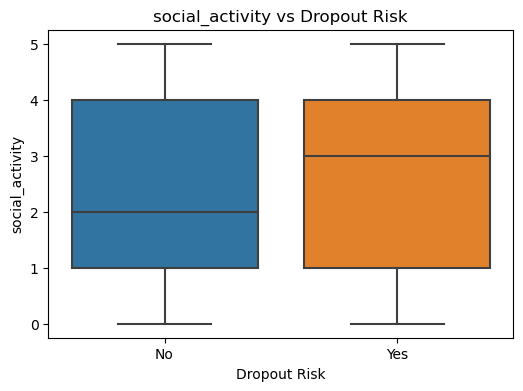

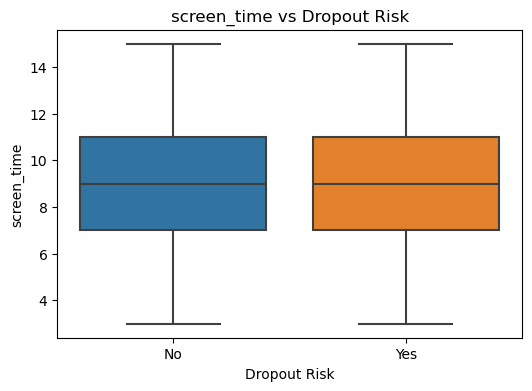

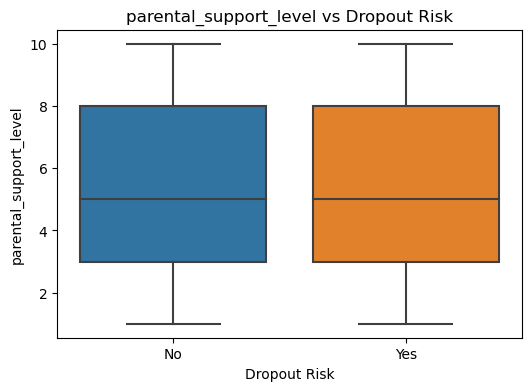

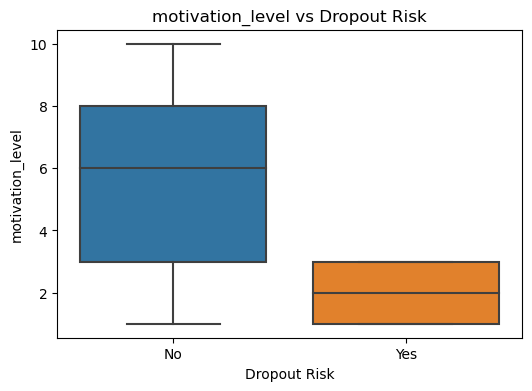

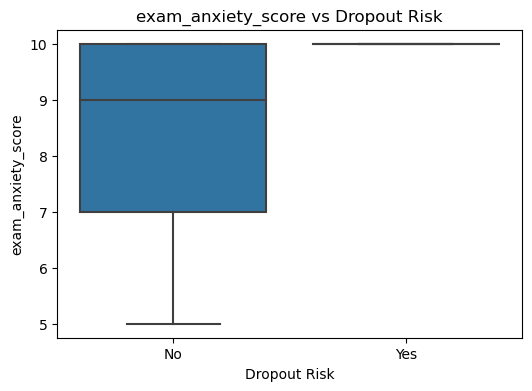

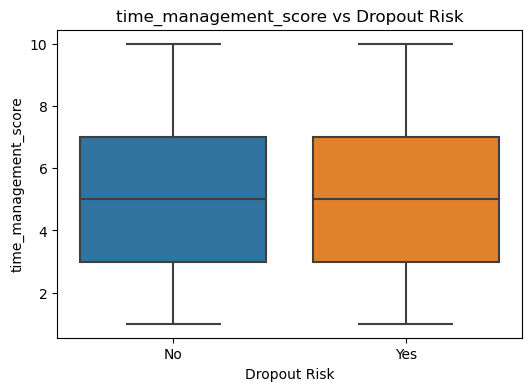

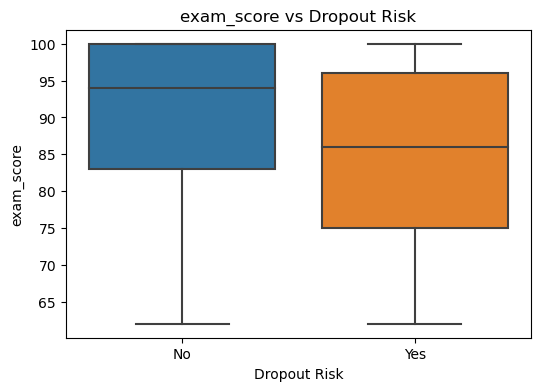

In [12]:
num_features = [
    "age",
    "study_hours_per_day",
    "social_media_hours",
    "netflix_hours",
    "attendance_percentage",
    "sleep_hours",
    "exercise_frequency",
    "mental_health_rating",
    "previous_gpa",
    "semester",
    "stress_level",
    "social_activity",
    "screen_time",
    "parental_support_level",
    "motivation_level",
    "exam_anxiety_score",
    "time_management_score",
    "exam_score"
]
for col in num_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(data=df, x="dropout_risk", y=col)
    plt.title(f"{col} vs Dropout Risk")
    plt.xlabel("Dropout Risk")
    plt.ylabel(col)
    plt.show()


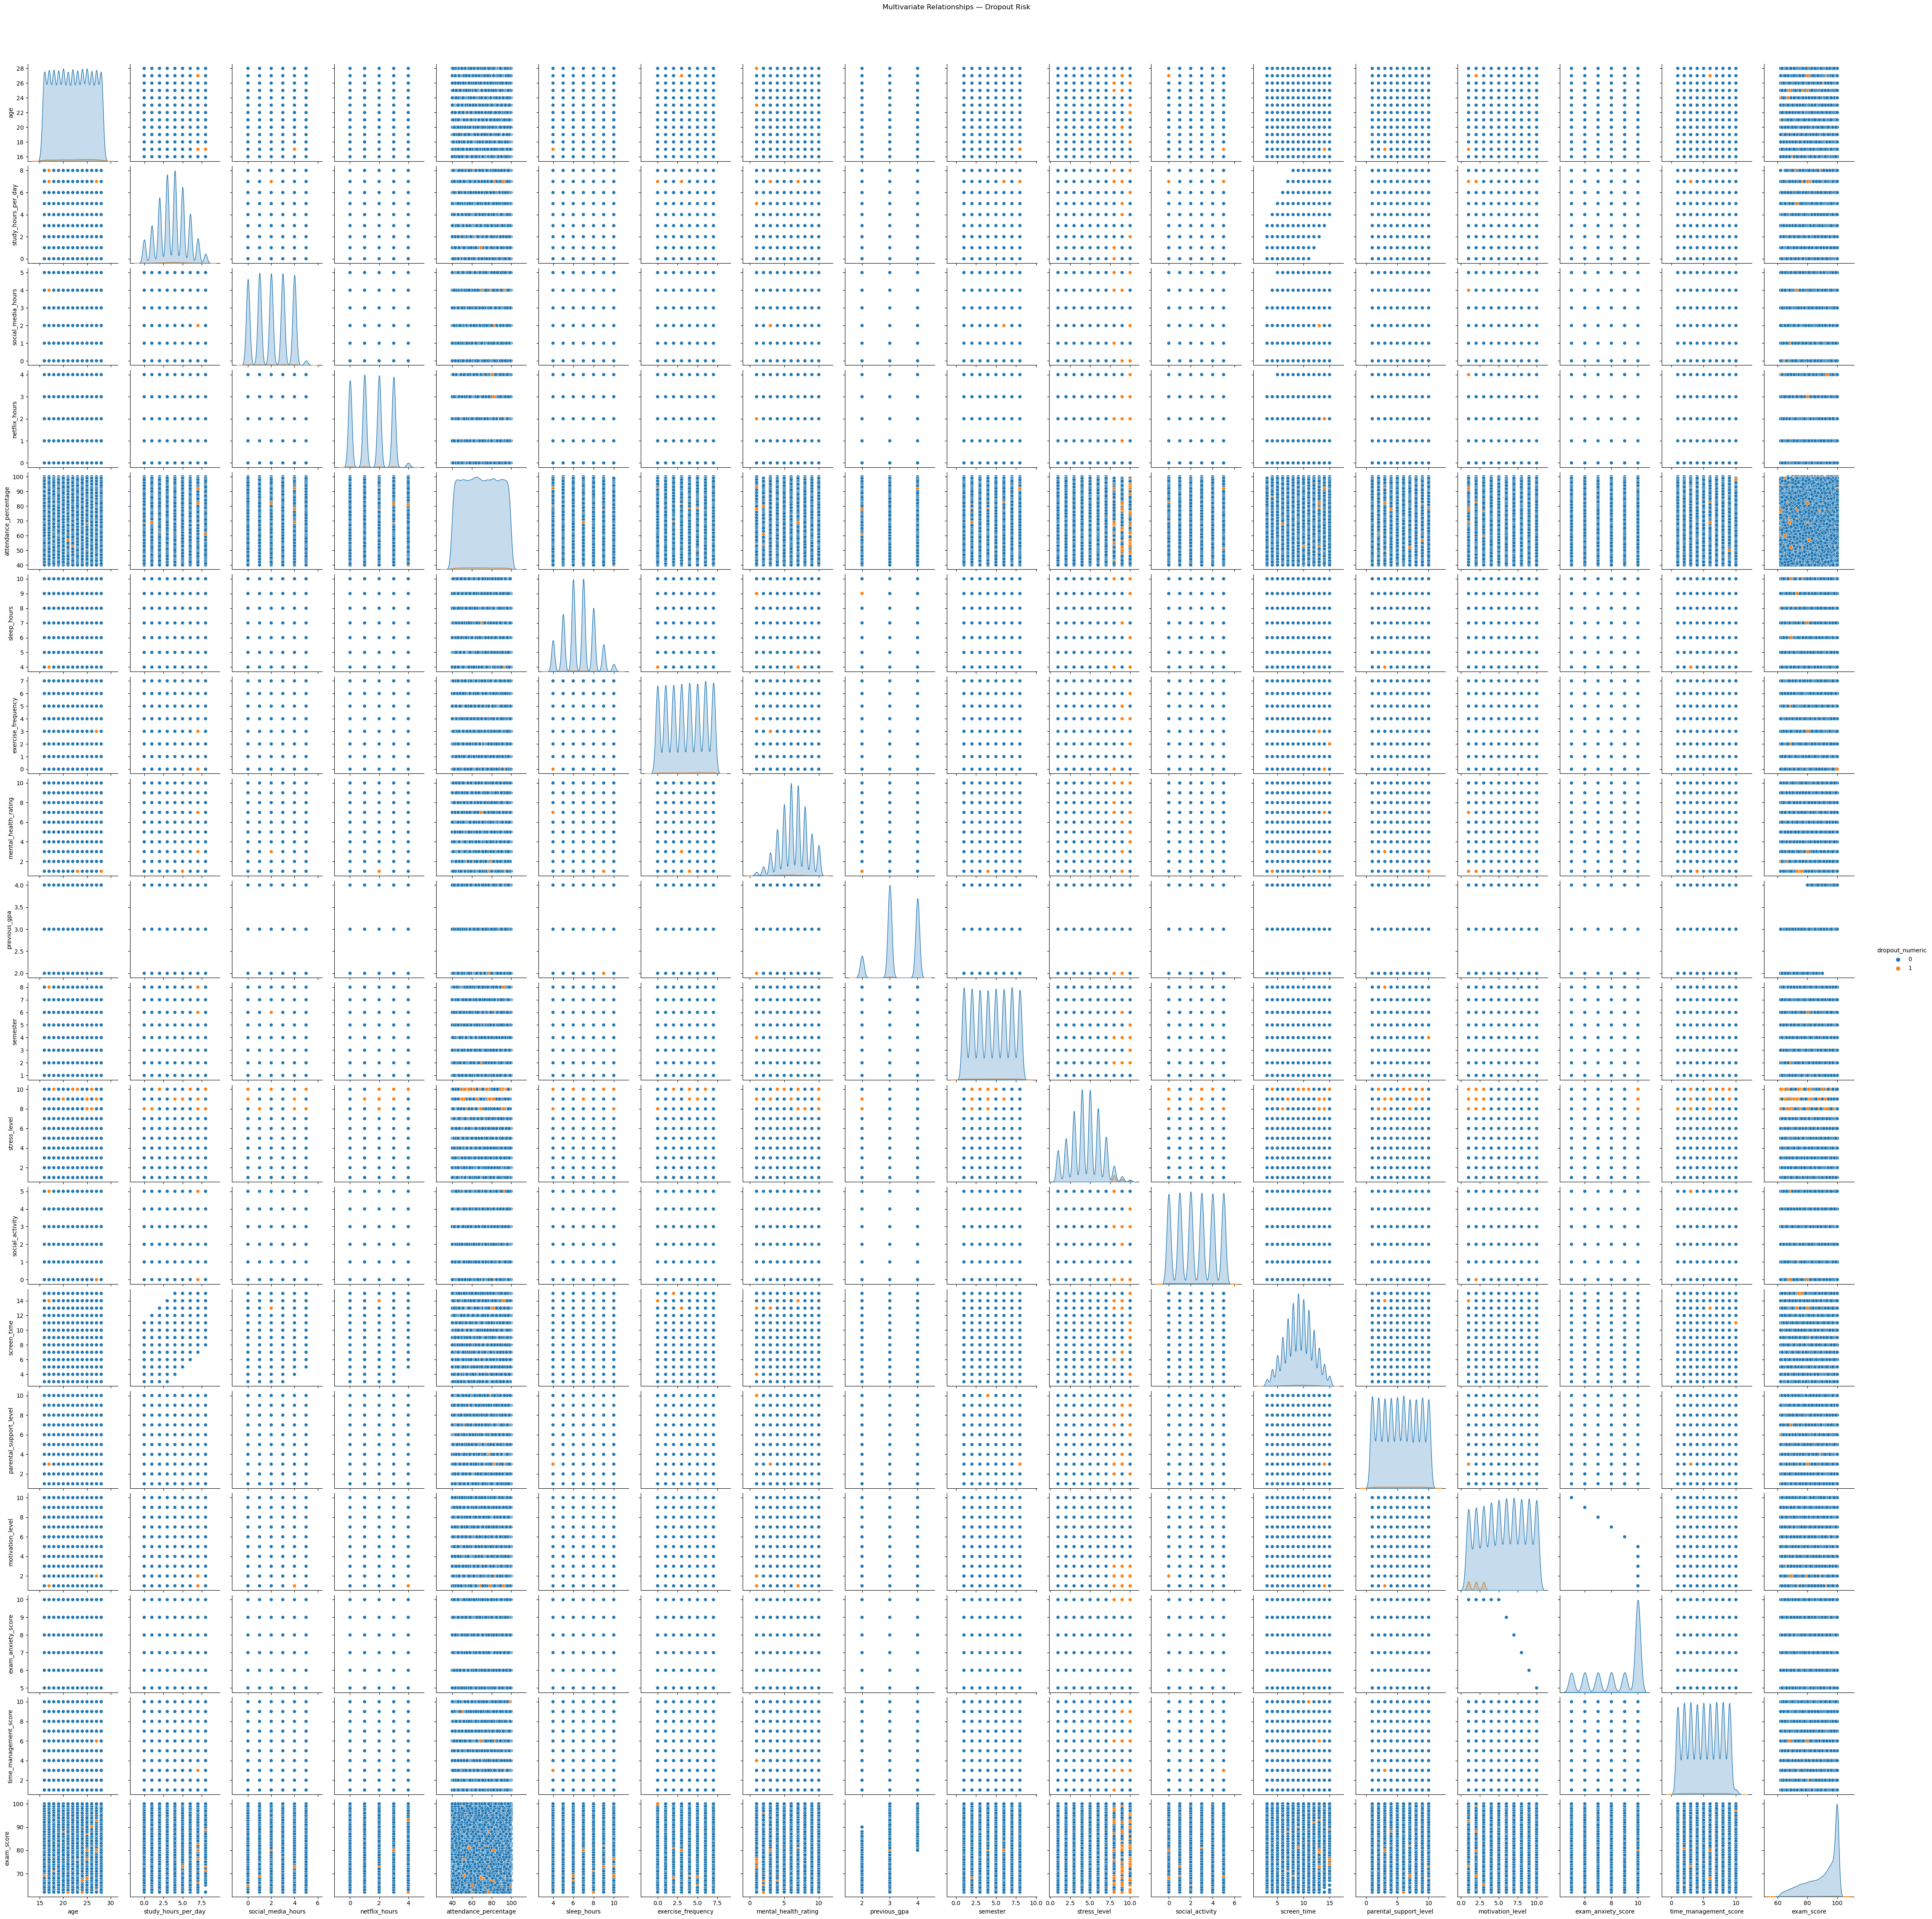

In [13]:
df["dropout_numeric"] = df["dropout_risk"].map({"No":0, "Yes":1})

multivariate_features = num_features + ["dropout_numeric"]

sns.pairplot(df[multivariate_features], hue="dropout_numeric")
plt.suptitle("Multivariate Relationships — Dropout Risk", y=1.02)
plt.show()


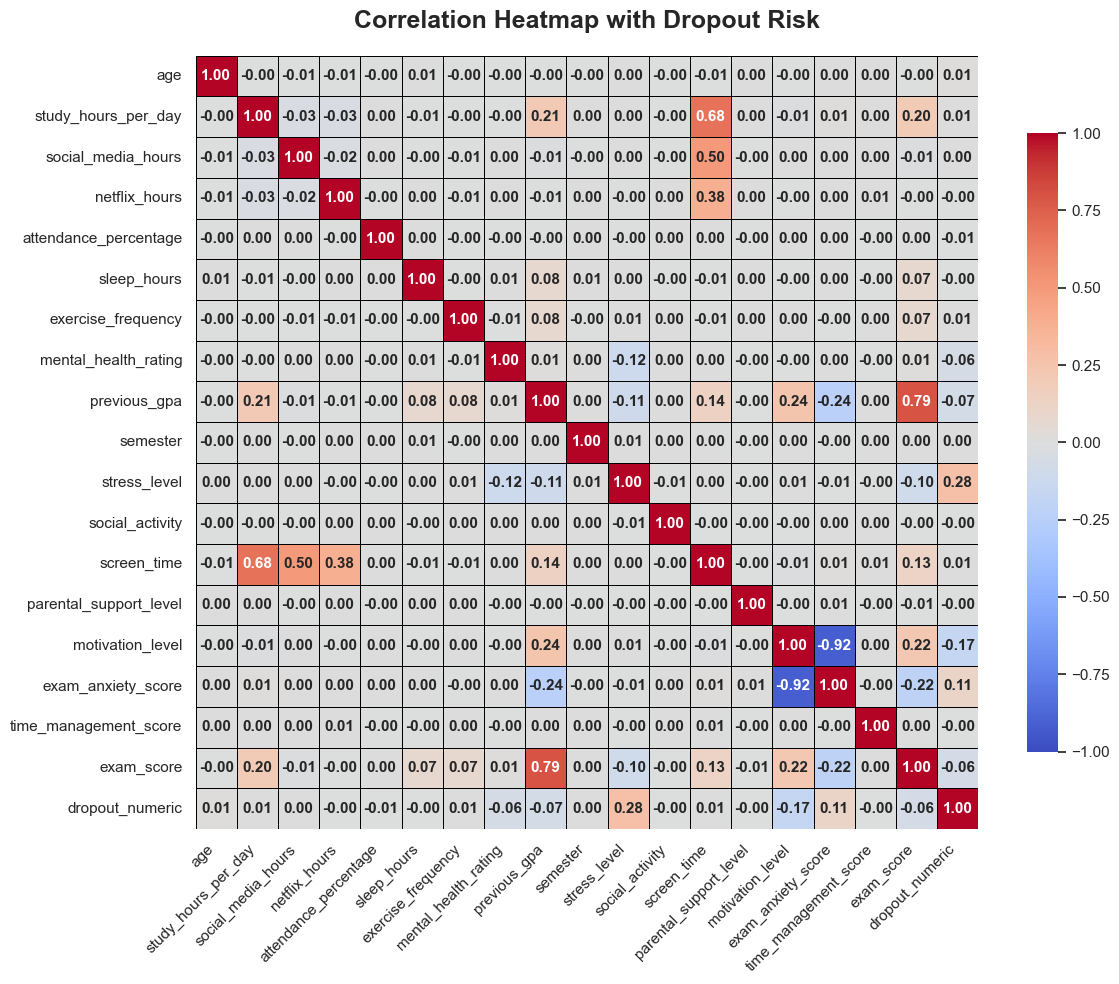


📌 Correlation with Dropout Risk (Sorted by Strength):

                        Correlation
dropout_numeric            1.000000
stress_level               0.275213
motivation_level          -0.169338
exam_anxiety_score         0.114593
previous_gpa              -0.071330
exam_score                -0.064634
mental_health_rating      -0.055660
age                        0.009333
study_hours_per_day        0.007482
exercise_frequency         0.007470
screen_time                0.007143
attendance_percentage     -0.006450
sleep_hours               -0.002761
time_management_score     -0.002710
social_media_hours         0.002705
netflix_hours             -0.001980
parental_support_level    -0.001472
social_activity           -0.000307
semester                   0.000131


In [14]:
corr_matrix = df[multivariate_features].corr()

plt.figure(figsize=(12, 10))
sns.set_theme(style="white")

heatmap = sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,       # consistent color scale
    linewidths=0.5,
    linecolor="black",
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 11, "weight": "bold"}  # better visibility
)

plt.title("Correlation Heatmap with Dropout Risk", fontsize=18, fontweight="bold", pad=20)
plt.xticks(rotation=45, ha="right", fontsize=11)
plt.yticks(rotation=0, fontsize=11)
plt.tight_layout()
plt.show()


# Sorted correlation values with dropout risk
corr_target = corr_matrix["dropout_numeric"].sort_values(key=abs, ascending=False)

print("\n📌 Correlation with Dropout Risk (Sorted by Strength):\n")
print(corr_target.to_frame().rename(columns={"dropout_numeric": "Correlation"}))


In [15]:
TOP_K = 6

# Top strongest numerical correlations with dropout risk
top_numerical_features = (
    corr_target
    .drop("dropout_numeric")     # remove target to avoid self-correlation
    .abs()
    .sort_values(ascending=False)
    .head(TOP_K)
    .index
    .tolist()
)

# Extra features you want to force include
extra_features = [
    "exercise_frequency",
    "sleep_hours",
    "attendance_percentage"
]

# Final unique list
final_numerical_features = list(dict.fromkeys(top_numerical_features + extra_features))

print("\nFinal Numerical Features for Modeling:")
print(final_numerical_features)



Final Numerical Features for Modeling:
['stress_level', 'motivation_level', 'exam_anxiety_score', 'previous_gpa', 'exam_score', 'mental_health_rating', 'exercise_frequency', 'sleep_hours', 'attendance_percentage']


In [16]:
# Identify categorical columns (excluding target)
categorical_cols_all = df.select_dtypes(include='object').columns.tolist()
categorical_cols_all.remove("dropout_risk")  # Target excluded

categorical_cols_all


['gender',
 'major',
 'part_time_job',
 'diet_quality',
 'parental_education_level',
 'internet_quality',
 'extracurricular_participation',
 'study_environment',
 'access_to_tutoring',
 'family_income_range',
 'learning_style']

In [17]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum()
    r, k = confusion_matrix.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

cat_corr_results = {}

for col in categorical_cols_all:
    contingency = pd.crosstab(df[col], df["dropout_risk"])
    c_v = cramers_v(contingency.to_numpy())
    cat_corr_results[col] = c_v

# Sort by highest impact on dropout risk
sorted_cat_corr = dict(sorted(cat_corr_results.items(), key=lambda x: x[1], reverse=True))

sorted_cat_corr


{'parental_education_level': 0.010423344030308236,
 'major': 0.009311086140280056,
 'study_environment': 0.009175206325529003,
 'diet_quality': 0.008624584532376255,
 'learning_style': 0.005129538706582986,
 'family_income_range': 0.00491023870591914,
 'gender': 0.004310442939892335,
 'internet_quality': 0.003899933533872733,
 'part_time_job': 0.0023414854468056857,
 'access_to_tutoring': 0.001028398600356182,
 'extracurricular_participation': 0.0002139187696579544}

In [18]:
threshold = 0.002

filtered_cat_features = [k for k, v in sorted_cat_corr.items() if v >= threshold]

# If more than 5 -> take top 5
selected_categorical_features = filtered_cat_features[:7]

print("\nSelected Categorical Features based on Updated Threshold:")
print(selected_categorical_features)



Selected Categorical Features based on Updated Threshold:
['parental_education_level', 'major', 'study_environment', 'diet_quality', 'learning_style', 'family_income_range', 'gender']


In [19]:
selected_features = final_numerical_features + selected_categorical_features

print("\nFINAL SELECTED FEATURES FOR MODEL TRAINING:\n", selected_features)



FINAL SELECTED FEATURES FOR MODEL TRAINING:
 ['stress_level', 'motivation_level', 'exam_anxiety_score', 'previous_gpa', 'exam_score', 'mental_health_rating', 'exercise_frequency', 'sleep_hours', 'attendance_percentage', 'parental_education_level', 'major', 'study_environment', 'diet_quality', 'learning_style', 'family_income_range', 'gender']


In [20]:
X = df[selected_features]
y = df["dropout_numeric"]

categorical_cols = X.select_dtypes(include="object").columns
numerical_cols = X.select_dtypes(include=np.number).columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)


In [21]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols)
])


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
import joblib


In [23]:
from sklearn.ensemble import VotingClassifier

hybrid_rf_xgb = VotingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(n_estimators=300, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42))
    ],
    voting='soft'
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=600),
    "SVC": SVC(probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42),
    "Hybrid RF + XGB": hybrid_rf_xgb
}




# ===============================
# 🏁 Train & Evaluate
# ===============================
results = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    preds = pipeline.predict(X_test)

    acc = accuracy_score(y_test, preds)
    precision = precision_score(y_test, preds)
    recall = recall_score(y_test, preds)
    f1 = f1_score(y_test, preds)

    results[name] = {
        "pipeline": pipeline,
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1_score": f1
    }

    print("\n==========", name, "==========")
    print(f"Accuracy : {acc:.8f}")
    print(f"Precision: {precision:.8f}")
    print(f"Recall   : {recall:.8f}")
    print(f"F1 Score : {f1:.8f}")
    print("\nClassification Report:\n", classification_report(y_test, preds))



========== Logistic Regression ==========
Accuracy : 0.99281477
Precision: 0.84297521
Recall   : 0.74181818
F1 Score : 0.78916828

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     14895
           1       0.84      0.74      0.79       275

    accuracy                           0.99     15170
   macro avg       0.92      0.87      0.89     15170
weighted avg       0.99      0.99      0.99     15170


========== SVC ==========
Accuracy : 0.99380356
Precision: 0.86055777
Recall   : 0.78545455
F1 Score : 0.82129278

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     14895
           1       0.86      0.79      0.82       275

    accuracy                           0.99     15170
   macro avg       0.93      0.89      0.91     15170
weighted avg       0.99      0.99      0.99     15170


========== Random Forest ==========
Accuracy : 0.

In [24]:
best_model_name = max(results, key=lambda x: results[x]["f1_score"])
best_pipeline = results[best_model_name]["pipeline"]

joblib.dump(best_pipeline, "best_drop_out_model.pkl")

print("\n🏆 BEST MODEL SELECTED BASED ON F1-SCORE:", best_model_name)
print("Model saved successfully as: best_drop_out_model.pkl\n")

print("Performance Metrics of Best Model:")
print(f"Accuracy : {results[best_model_name]['accuracy']:.4f}")
print(f"Precision: {results[best_model_name]['precision']:.4f}")
print(f"Recall   : {results[best_model_name]['recall']:.4f}")
print(f"F1 Score : {results[best_model_name]['f1_score']:.4f}")



🏆 BEST MODEL SELECTED BASED ON F1-SCORE: Random Forest
Model saved successfully as: best_drop_out_model.pkl

Performance Metrics of Best Model:
Accuracy : 0.9983
Precision: 0.9136
Recall   : 1.0000
F1 Score : 0.9549


In [25]:

performance_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Accuracy": [results[m]["accuracy"] for m in results],
    "Precision": [results[m]["precision"] for m in results],
    "Recall": [results[m]["recall"] for m in results],
    "F1-score": [results[m]["f1_score"] for m in results]
})

# Sort table by F1-score (best at top)
performance_df = performance_df.sort_values(by="F1-score", ascending=False).reset_index(drop=True)

# Round the values for better readability
performance_df = performance_df.round(4)

print("\n📊 Model Performance Comparison Table:\n")
display(performance_df)



📊 Model Performance Comparison Table:



,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.9983,0.9136,1.0000,0.9549
1,Hybrid RF + XGB,0.9982,0.9130,0.9927,0.9512
2,XGBoost,0.9980,0.9153,0.9818,0.9474
3,SVC,0.9938,0.8606,0.7855,0.8213
4,Logistic Regression,0.9928,0.8430,0.7418,0.7892


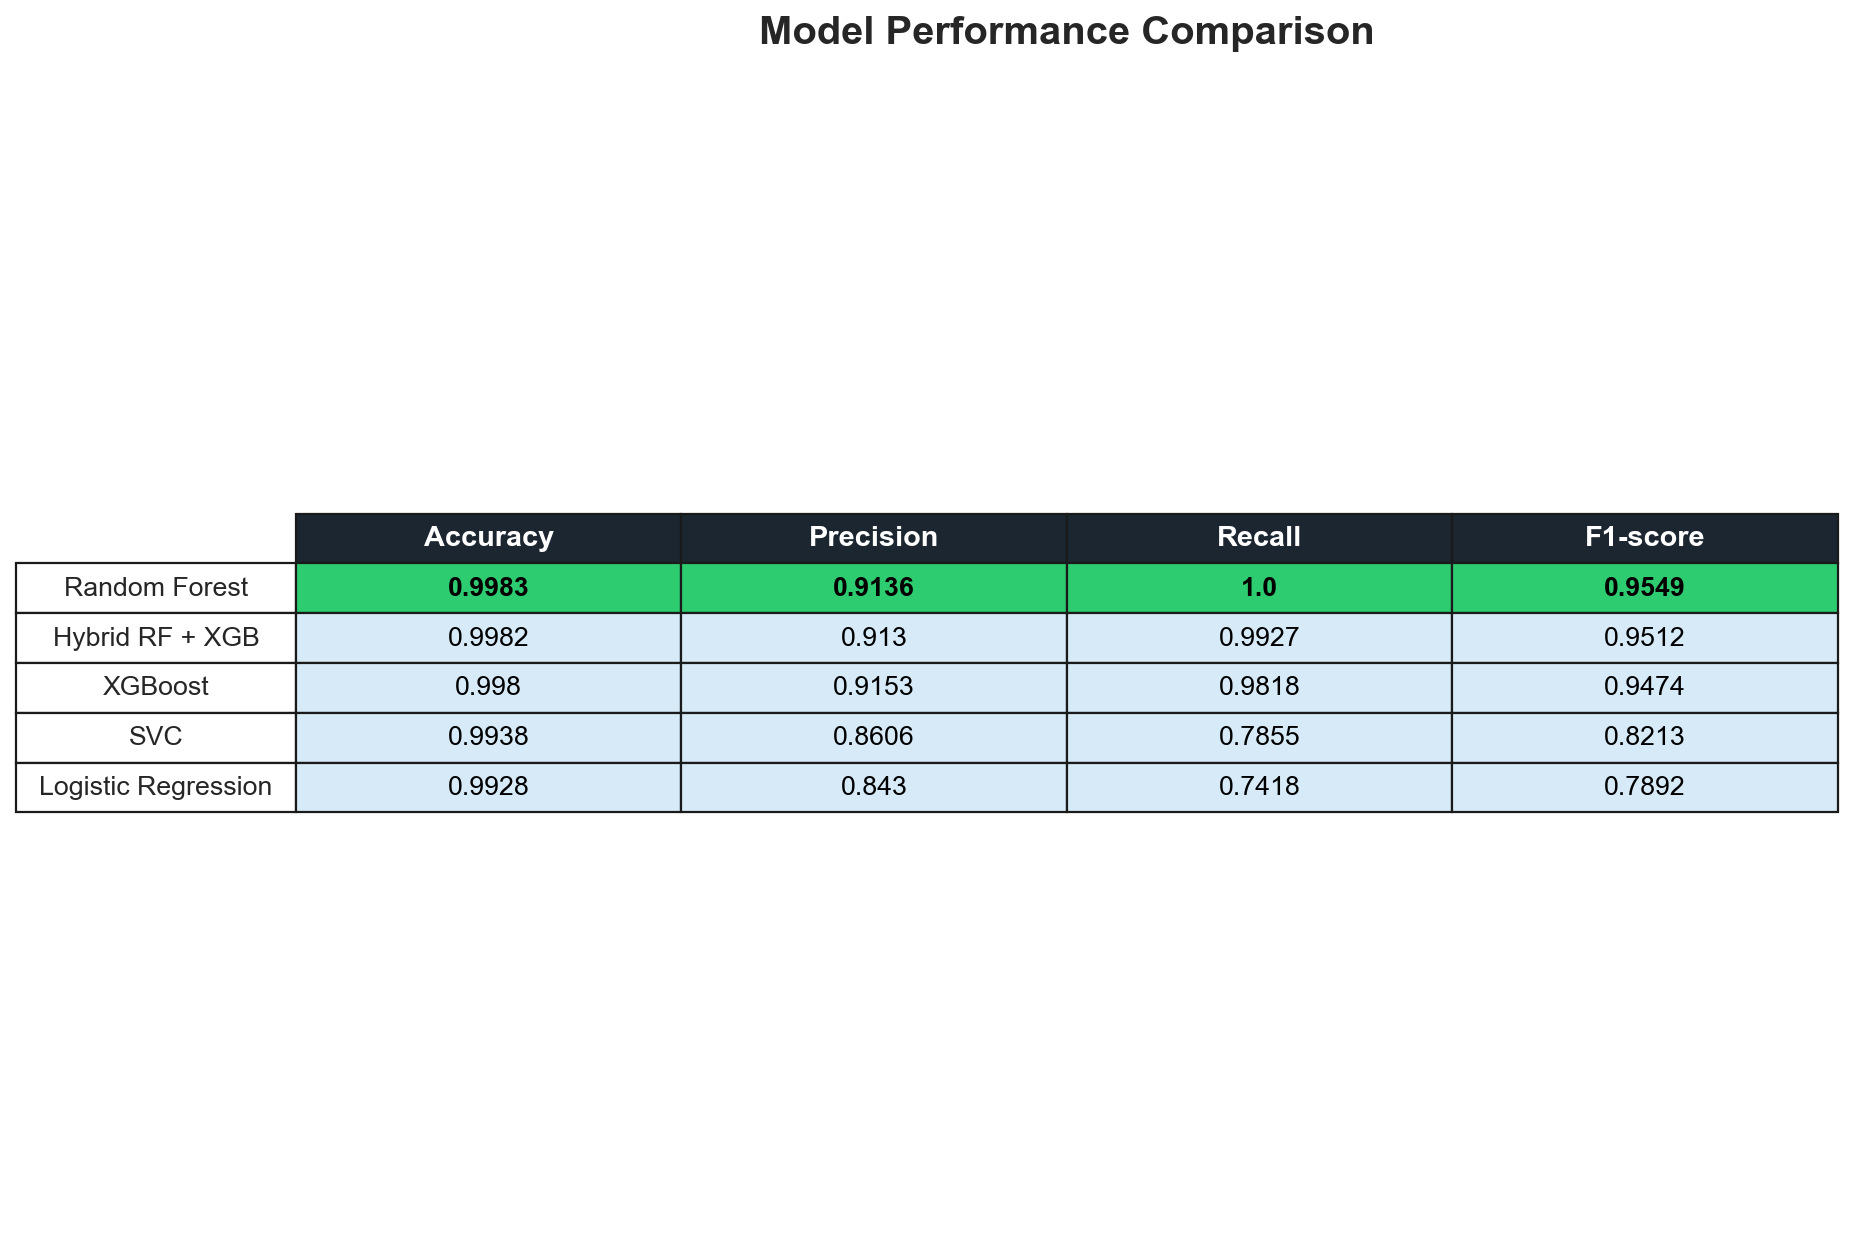

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Prepare DataFrame
results_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Accuracy": [results[m]["accuracy"] for m in results],
    "Precision": [results[m]["precision"] for m in results],
    "Recall": [results[m]["recall"] for m in results],
    "F1-score": [results[m]["f1_score"] for m in results]
})

results_df = results_df.sort_values(by="F1-score", ascending=False).reset_index(drop=True)
results_df = results_df.round(4)
results_df.set_index("Model", inplace=True)

# Plot Table
plt.figure(figsize=(12, 3 + len(results_df)), dpi=160)
plt.title("Model Performance Comparison", fontsize=18, fontweight='bold', pad=20)

# Colors
header_color = "#1B2631"
best_color = "#2ECC71"
normal_color = "#D6EAF8"
text_color = "black"

# Draw Table
table = plt.table(
    cellText=results_df.values,
    rowLabels=results_df.index,
    colLabels=results_df.columns,
    cellLoc='center',
    rowLoc='center',
    loc='center'
)

# Formatting styles
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.6)

# Header styling
for col in range(len(results_df.columns)):
    cell = table[0, col]
    cell.set_facecolor(header_color)
    cell.set_text_props(color="white", weight='bold', fontsize=13)

# Highlight best model row (first row after sorting)
for j in range(len(results_df.columns)):
    cell = table[1, j]  # first data row
    cell.set_facecolor(best_color)
    cell.set_text_props(weight='bold', color=text_color)

# Style remaining rows
for i in range(2, len(results_df) + 1):
    for j in range(len(results_df.columns)):
        table[i, j].set_facecolor(normal_color)
        table[i, j].set_text_props(color=text_color)

# Remove axes for clean display
plt.gca().set_axis_off()
plt.tight_layout()
plt.show()


<Figure size 1200x600 with 0 Axes>

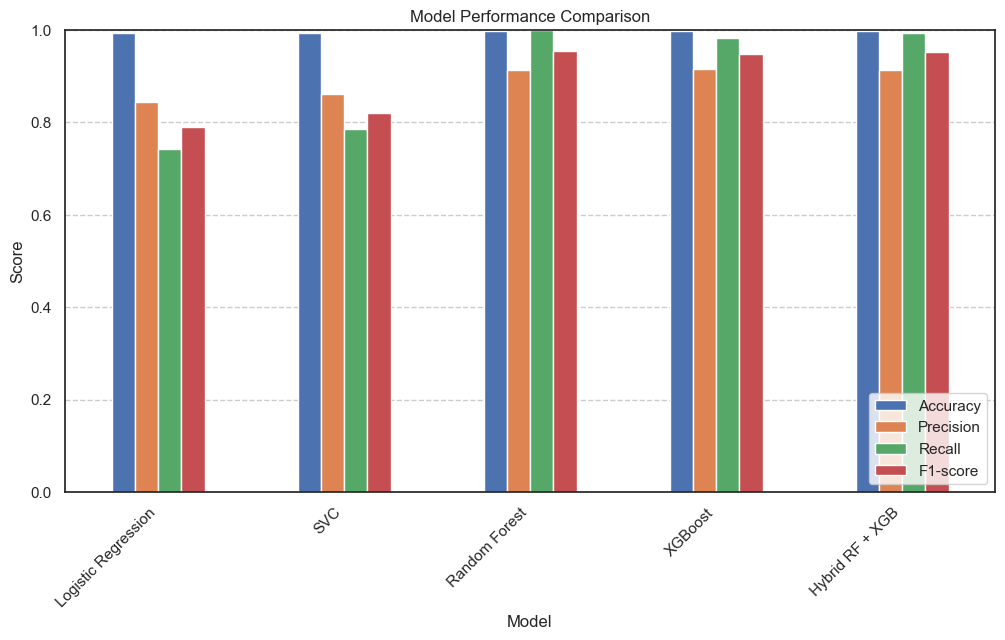

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create DataFrame for visualization
model_names = []
accuracies = []
precisions = []
recalls = []
f1_scores = []

for name, metrics in results.items():
    model_names.append(name)
    accuracies.append(metrics['accuracy'])
    precisions.append(metrics['precision'])
    recalls.append(metrics['recall'])
    f1_scores.append(metrics['f1_score'])

performance_df = pd.DataFrame({
    "Model": model_names,
    "Accuracy": accuracies,
    "Precision": precisions,
    "Recall": recalls,
    "F1-score": f1_scores
})

# Plot Comparison Graph
plt.figure(figsize=(12,6))
performance_df.set_index("Model").plot(kind="bar", figsize=(12,6))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=45, ha='right')
plt.legend(loc="lower right")
plt.grid(axis='y', linestyle='--')
plt.show()


<Figure size 1200x600 with 0 Axes>

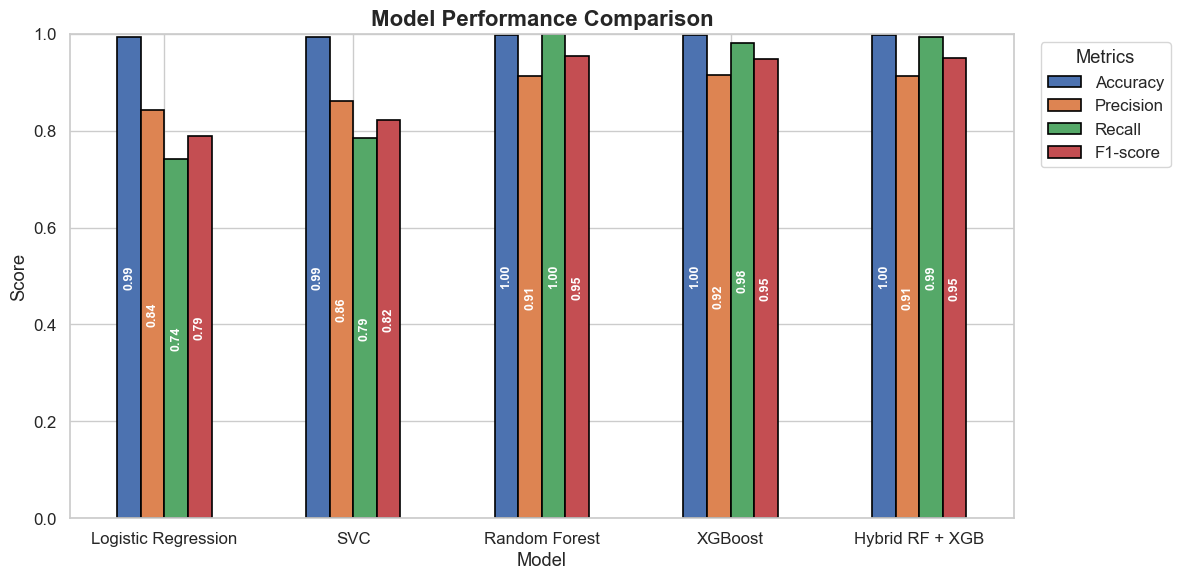

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", font_scale=1.1)

plt.figure(figsize=(12, 6))

ax = performance_df.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    edgecolor='black',
    linewidth=1.2
)

plt.title("Model Performance Comparison", fontsize=16, weight='bold')
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Metrics", bbox_to_anchor=(1.02, 1), loc='upper left')

# Vertical value labels centered inside bars
for p in ax.patches:
    value = p.get_height()
    ax.text(
        p.get_x() + p.get_width() / 2.,  # X center of bar
        value / 2,                       # Y center of bar
        f"{value:.2f}",
        ha='center', va='center',
        rotation=90,                     # Vertical text
        color='white',
        fontsize=9,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()


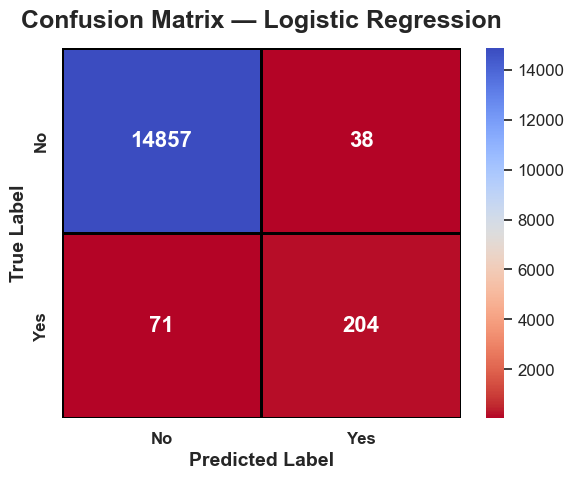

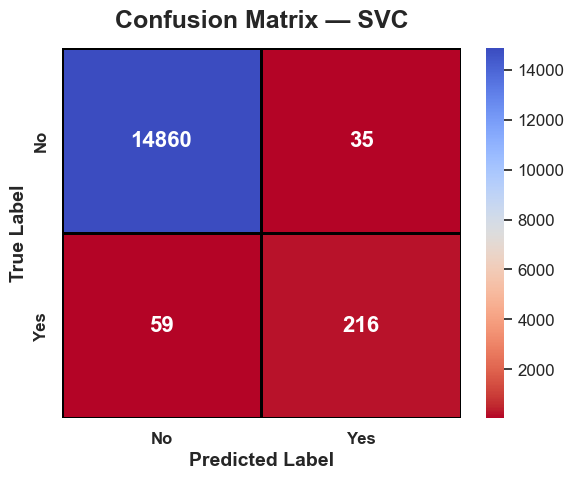

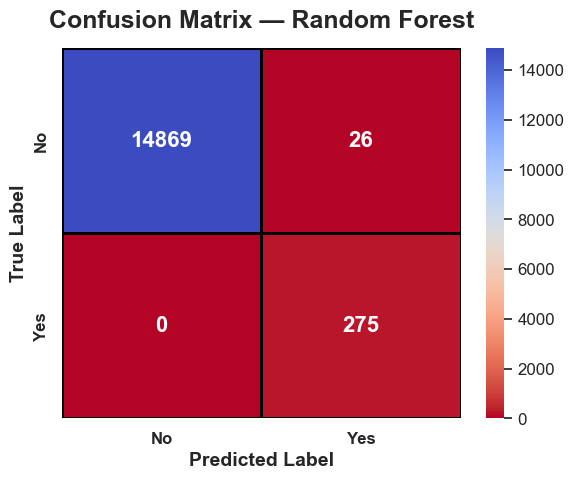

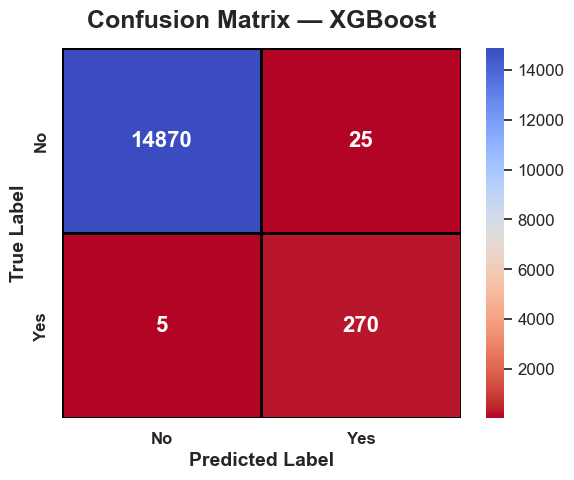

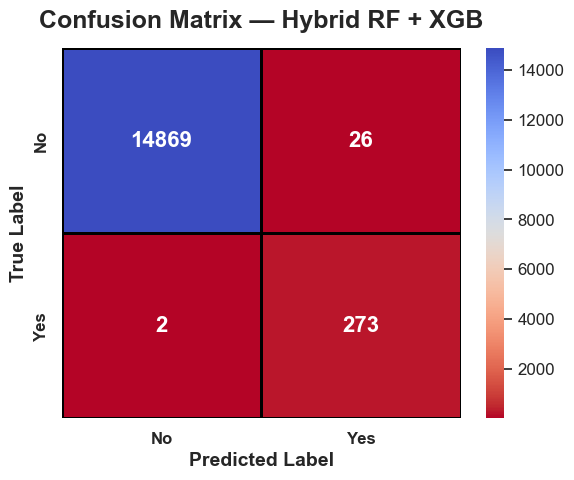

In [29]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

for name, model_info in results.items():

    # Predict again for confusion matrix
    y_pred = model_info["pipeline"].predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(6,5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap="coolwarm_r",
        linewidths=2,
        linecolor='black',
        annot_kws={"size": 16, "weight": "bold"},
    )

    plt.title(f"Confusion Matrix — {name}", fontsize=18, fontweight="bold", pad=15)
    plt.xlabel("Predicted Label", fontsize=14, fontweight="bold")
    plt.ylabel("True Label", fontsize=14, fontweight="bold")

    plt.xticks(ticks=[0.5,1.5], labels=["No", "Yes"], fontsize=12, fontweight="bold")
    plt.yticks(ticks=[0.5,1.5], labels=["No", "Yes"], fontsize=12, fontweight="bold")

    plt.tight_layout()
    plt.show()


<Figure size 600x500 with 0 Axes>

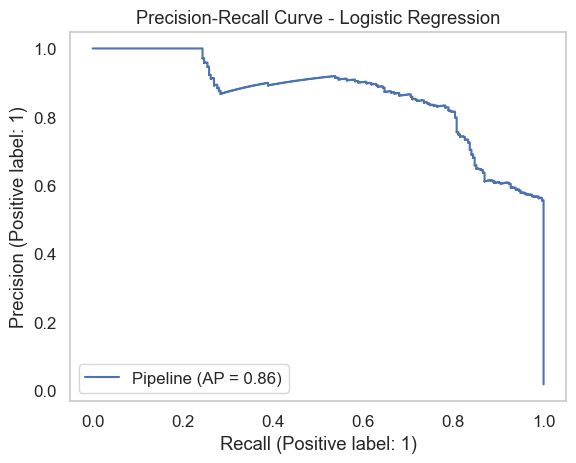

<Figure size 600x500 with 0 Axes>

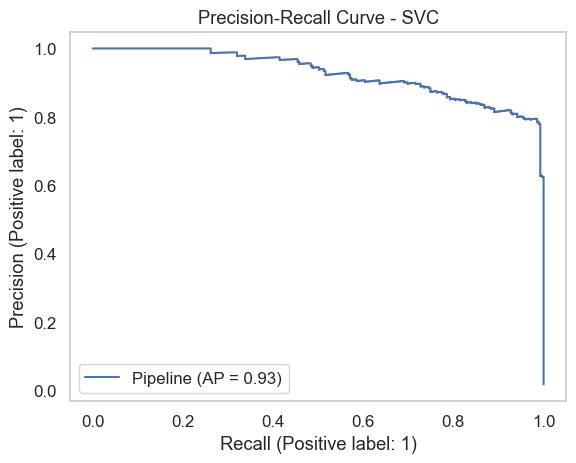

<Figure size 600x500 with 0 Axes>

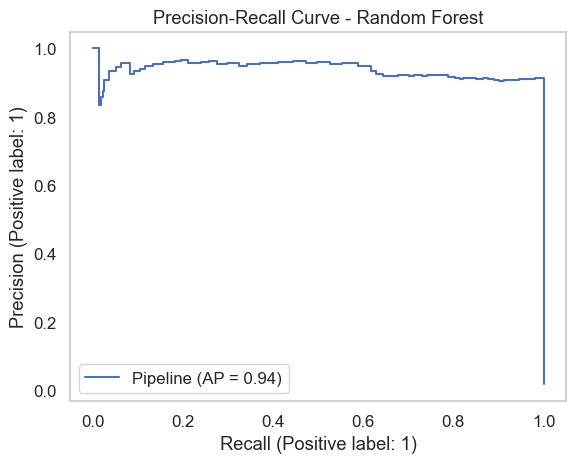

<Figure size 600x500 with 0 Axes>

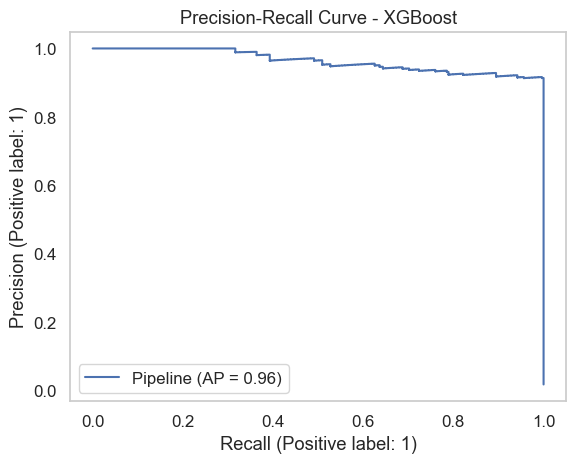

<Figure size 600x500 with 0 Axes>

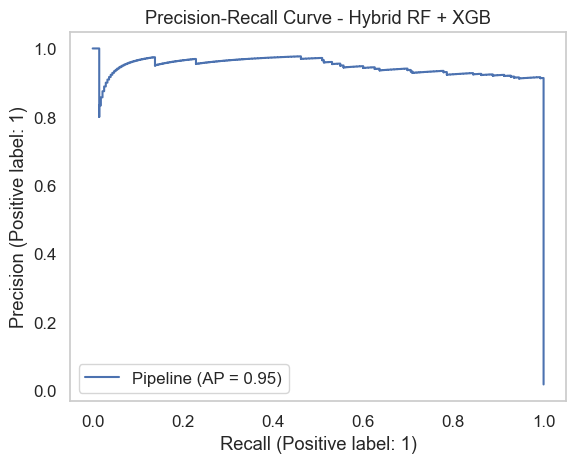

In [30]:
from sklearn.metrics import PrecisionRecallDisplay

for name, model in results.items():
    plt.figure(figsize=(6,5))
    PrecisionRecallDisplay.from_estimator(model["pipeline"], X_test, y_test)
    plt.title(f"Precision-Recall Curve - {name}")
    plt.grid()
    plt.show()


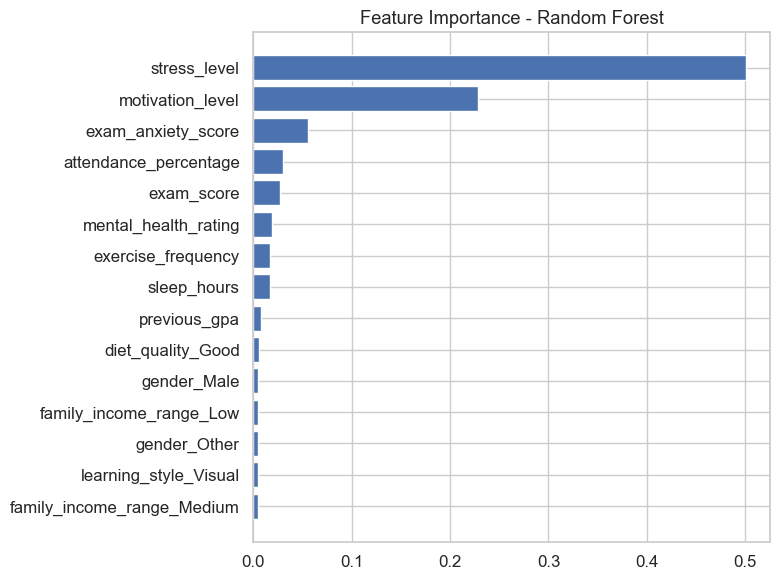

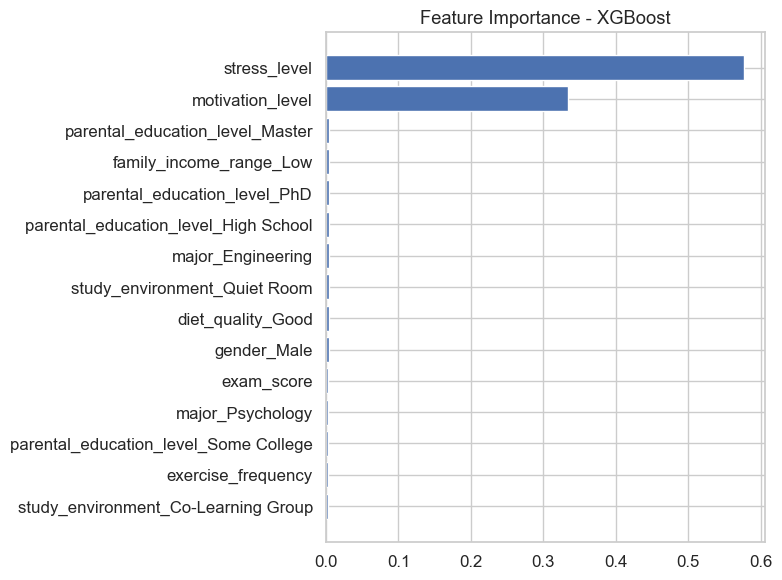

In [31]:
import numpy as np

for name in ["Random Forest", "XGBoost"]:
    model = results[name]["pipeline"]["model"]
    ohe = results[name]["pipeline"]["preprocess"].named_transformers_["cat"]
    cat_feature_names = ohe.get_feature_names_out(categorical_cols)

    feature_names = list(numerical_cols) + list(cat_feature_names)
    importances = model.feature_importances_

    sorted_idx = np.argsort(importances)[-15:]  # Top 15 features

    plt.figure(figsize=(8,6))
    plt.barh(np.array(feature_names)[sorted_idx], importances[sorted_idx])
    plt.title(f"Feature Importance - {name}")
    plt.tight_layout()
    plt.show()


In [32]:
user_input = {
    # Final Numerical Features
    "stress_level": 3,
    "motivation_level": 8,
    "exam_anxiety_score": 4,
    "previous_gpa": 3,
    "exam_score": 75,
    "mental_health_rating": 7,
    "exercise_frequency": 3,
    "sleep_hours": 7,
    "attendance_percentage": 88,

    # Final Categorical Features
    "gender": "Male",
    "major": "Computer Science",
    "study_environment": "Quiet Room",
    "diet_quality": "Good",
    "learning_style": "Visual",
    "family_income_range": "Medium",
    "parental_education_level": "Bachelor"
}


In [33]:
# Load Best Model
loaded_model = joblib.load("best_drop_out_model.pkl")

user_df = pd.DataFrame([user_input])

# Predict
prediction = loaded_model.predict(user_df)[0]
probability = loaded_model.predict_proba(user_df)[0][1]

if prediction == 1:
    print("🎯 Prediction: HIGH Dropout Risk ⚠️")
else:
    print("🎯 Prediction: LOW Dropout Risk 👍")

print(f"Dropout Probability: {probability:.2f}")


🎯 Prediction: LOW Dropout Risk 👍
Dropout Probability: 0.00


In [34]:
user_input = {
    # Final Numerical Features
    "stress_level": 9,
    "motivation_level": 2,
    "exam_anxiety_score": 9,
    "previous_gpa": 4,
    "exam_score": 50,
    "mental_health_rating": 3,
    "exercise_frequency": 0,
    "sleep_hours": 4,
    "attendance_percentage": 55,

    # Final Categorical Features
    "gender": "Other",
    "major": "Psychology",
    "study_environment": "Dorm",
    "diet_quality": "Poor",
    "learning_style": "Kinesthetic",
    "family_income_range": "Low",
    "parental_education_level": "High School"
}


In [35]:
loaded_model = joblib.load("best_drop_out_model.pkl")

user_df = pd.DataFrame([user_input])

prediction = loaded_model.predict(user_df)[0]
probability = loaded_model.predict_proba(user_df)[0][1]
probability = round(probability, 2)

print(f"Dropout Probability: {probability}")

# Risk Level Interpretation
if probability >= 0.7:
    print("🚨 HIGH Dropout Risk — Immediate Intervention Required!")
elif probability >= 0.3:
    print("⚠️ MEDIUM Dropout Risk — Provide Extra Support and Guidance.")
else:
    print("👍 LOW Dropout Risk — Student is Performing Well!")


Dropout Probability: 0.41
⚠️ MEDIUM Dropout Risk — Provide Extra Support and Guidance.
